# Project 2 - Text-to-Image Generation
## Milestone 1: Dataset, CLIP Embeddings, and Baseline Generation

**IE 7615** - Project 2, Milestone 1

**David Fung**

This milestone prepares the foundational pipeline for a text-to-image generative model: a curated Flickr30k image caption subset, a CLIP text image embedding pipeline, and a baseline gallery of prompt image samples generated from a pretrained Stable Diffusion pipeline. All experiments are conducted in a single notebook.

In [25]:
import os
import time
import random
import shutil
import json
import glob
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

import torch
from transformers import CLIPProcessor, CLIPModel
from diffusers import StableDiffusionPipeline
from sklearn.decomposition import PCA
from tqdm.notebook import tqdm 

print(f"PyTorch:  {torch.__version__}")
print(f"CUDA:     {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU:      {torch.cuda.get_device_name(0)}")

PyTorch:  2.14.1+cpu
CUDA:     False


In [26]:
# PROJECT CONSTANTS

GLOBAL_SEED = 42
random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)
torch.manual_seed(GLOBAL_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(GLOBAL_SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Models
CLIP_MODEL_NAME = "openai/clip-vit-base-patch32"
SD_MODEL_NAME   = "runwayml/stable-diffusion-v1-5"

# Generation settings
IMG_SIZE         = (512,512)
NUM_GENERATIONS  = 16
GUIDANCE_SCALE   = 10.0
NUM_INFER_STEPS  = 50
NV_SAMPLES       = 4

# Dataset curation
DATASET_NAME      = "umaru97/flickr30k_train_val_test"
MIN_CAPTION_WORDS = 8
MAX_CAPTION_WORDS = 200
MAX_PAIRS         = 5000

# Paths
DATA_DIR      = "../data"
CURATED_DIR   = os.path.join(DATA_DIR, "curated")
GALLERY_DIR   = "gallery"

os.makedirs(CURATED_DIR, exist_ok=True)
os.makedirs(GALLERY_DIR, exist_ok=True)

In [27]:
def clean_caption(text):
    """Normalise a caption: lowercase, collapse whitespace."""
    return ' '.join(text.lower().split())

def caption_passes(text):
    """Quality heuristic: word count in range, no URL, no non-alpha spam."""
    words = len(text.split())
    if not (MIN_CAPTION_WORDS <= words <= MAX_CAPTION_WORDS):
        return False
    if 'http' in text or 'www.' in text:
        return False
    alpha_ratio = sum(c.isalpha() or c.isspace() for c in text) / max(len(text), 1)
    return alpha_ratio > 0.85

def display_pairs(images, captions, n=4, title="Sample pairs"):
    """Show a grid of n images with their captions."""
    fig, axes = plt.subplots(1, n, figsize=(3 * n, 3.5))
    if n == 1:
        axes = [axes]
    for i, ax in enumerate(axes):
        ax.imshow(images[i])
        ax.set_title(captions[i][:70], fontsize=8)
        ax.axis("off")
    plt.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()

def process_and_save_image(source_img, target_path, size):
    """The robust worker: Resize, RGB-convert, and Save."""
    try:
        # 1. Ensure 3-channel RGB (prevents alpha/transparency errors)
        img = source_img.convert("RGB")
        
        # 2. High-quality Center Crop (preserves aspect ratio)
        img = ImageOps.fit(img, size, method=Image.Resampling.LANCZOS)
        
        # 3. Save with optimization
        img.save(target_path, format="JPEG", quality=95, optimize=True)
        return True
    except Exception as e:
        print(f"  ❌ Error processing {os.path.basename(target_path)}: {e}")
        return False

In [28]:
import matplotlib.pyplot as plt
import textwrap
from PIL import Image

def display_experiment_feed(images, captions, title="Experiment Results"):
    """
    Displays images in a single vertical column (1 image per row).
    """
    n = len(images)
    if n == 0:
        print("No images to display.")
        return

    # 1. Setup: One column, 'n' rows.
    fig, axes = plt.subplots(n, 1, figsize=(8, 5 * n))
    
    if n == 1:
        axes = [axes]

    print(f"--- Displaying {n} items in Feed View ---")

    # 2. The Loop
    for i in range(n):
        ax = axes[i]

        ax.imshow(images[i])
        
        # 3. Handle Caption Wrapping
        wrapped_text = textwrap.wrap(captions[i], width=50)
        caption_str = "\n".join(wrapped_text)
        
        # 4. Place text BELOW the image
        ax.text(0.5, -0.15, caption_str, 
                transform=ax.transAxes, 
                ha='center', va='top', 
                fontsize=11, 
                fontweight='medium',
                linespacing=1.5)
        
        ax.axis("off")

    # 5. Final Figure Formatting
    plt.suptitle(title, fontsize=16, fontweight='bold', y=1.01)
    
    plt.tight_layout(pad=4.0) 
    plt.show()

## Task 1 - Dataset Selection and Preprocessing

This task curates a working subset of Flickr30k image caption pairs.

1. Load the Flickr30k dataset from Hugging Face.
2. Apply caption cleaning: lowercasing, whitespace normalisation, word-count filter (~150 words), URL removal, deduplication.
3. Resize all images to 224x224 and normalise to [0, 1].
4. Save the curated subset as a JSON manifest alongside resized images.
5. Display a summary table and sample pairs.

In [29]:
# Step 1 — Load Flickr30k from Hugging Face
from datasets import load_dataset, load_from_disk

def get_dataset(dataset_name, raw_path):
    """
    Smart loader: 
    1. Checks if a local 'raw' version exists.
    2. If yes, loads it instantly from disk.
    3. If no, downloads from HF, saves it to the raw path, then returns it.
    """
    if os.path.exists(raw_path):
        print(f"--- Found local raw dataset at {raw_path}. Loading from disk... ---")
        return load_from_disk(raw_path)
    else:
        print(f"--- Raw dataset not found. Downloading {dataset_name} from Hugging Face... ---")
        # This is the slow part (Internet dependent)
        dataset = load_dataset(dataset_name) 
        
        print(f"--- Saving dataset to {raw_path} for future use... ---")
        dataset.save_to_disk(raw_path)
        return dataset

RAW_DATA_DIR = os.path.join(DATA_DIR, "raw_flickr30k")
ds = get_dataset(DATASET_NAME, RAW_DATA_DIR)


--- Found local raw dataset at ../data\raw_flickr30k. Loading from disk... ---


In [30]:
# Check dataset type

print(f"Type of ds: {type(ds)}")

if isinstance(ds, dict) or hasattr(ds, 'keys'):
    print(f"Found DatasetDict keys: {list(ds.keys())}")
    # Target the 'train' split (or whichever split you want to use)
    target_split = 'train' 
    if target_split in ds:
        print(f"✅ Switching focus to: {target_split}")
        ds = ds[target_split]
    else:
        # Fallback: if 'train' isn't there, take the first available split
        first_key = list(ds.keys())[0]
        print(f"⚠️ 'train' not found. Using first available split: {first_key}")
        ds = ds[first_key]
else:
    print("✅ ds is already a Dataset object.")


Type of ds: <class 'datasets.dataset_dict.DatasetDict'>
Found DatasetDict keys: ['train', 'val', 'test']
✅ Switching focus to: train


In [31]:
# Step 2 - Metadata Filtering

curated_metadata = []
id_to_index_array = {} 
seen_captions = set()
seen_images = set()
stats = {'total_scanned': 0, 'bad_caption': 0, 'duplicate_img': 0, 'duplicate_cap': 0, 'kept': 0}

print("--- Starting Metadata Scan ---")

for idx, item in enumerate(tqdm(ds, desc="Scanning Dataset")):
    stats['total_scanned'] += 1
    
    if len(curated_metadata) >= MAX_PAIRS:
        break

    img_id = item['img_id']
    caption_list = item['caption'] 

    if img_id in seen_images:
        stats['duplicate_img'] += 1
        continue

    found_valid_for_this_img = False
    for cap in caption_list:
        clean_cap = clean_caption(cap)
        
        if not (MIN_CAPTION_WORDS <= len(clean_cap.split()) <= MAX_CAPTION_WORDS) or not caption_passes(clean_cap):
            stats['bad_caption'] += 1
            continue

        if clean_cap in seen_captions:
            stats['duplicate_cap'] += 1
            continue

        curated_metadata.append({'image_id': img_id, 'caption': clean_cap})
        id_to_index_array[img_id] = idx 
        
        seen_captions.add(clean_cap)
        seen_images.add(img_id)
        stats['kept'] += 1
        found_valid_for_this_img = True
        break 
    
    if not found_valid_for_this_img:
        stats['bad_caption'] += 1

# Save the manifest
df_curated = pd.DataFrame(curated_metadata)
df_curint_path = os.path.join(CURATED_DIR, "manifest.csv")
df_curated.to_csv(df_curint_path, index=False)

print(f"\n--- Pass 1 Complete ---")
print(f"📊 Stats: {stats}")
display(df_curated.head())

--- Starting Metadata Scan ---


Scanning Dataset:   0%|          | 0/29000 [00:00<?, ?it/s]


--- Pass 1 Complete ---
📊 Stats: {'total_scanned': 5006, 'bad_caption': 44, 'duplicate_img': 0, 'duplicate_cap': 0, 'kept': 5000}


,image_id,caption
0,0,two young guys with shaggy hair look at their ...
1,1,several men in hard hats are operating a giant...
2,2,a child in a pink dress is climbing up a set o...
3,3,someone in a blue shirt and hat is standing on...
4,4,"two men, one in a gray shirt, one in a black s..."


In [32]:
# Step 3 Image processing

print(f"--- Starting Image Processing: Saving to {CURATED_DIR} ---")
processed_count = 0

for _, row in tqdm(df_curated.iterrows(), total=len(df_curated), desc="Processing Images"):
    img_id = row['image_id']
    
    # Use the map to find the index in the original dataset
    original_idx = id_to_index_array[img_id]
    source_img_obj = ds[original_idx]['image']
    
    target_path = os.path.join(CURATED_DIR, img_id)
    
    if process_and_save_image(source_img_obj, target_path, IMG_SIZE):
        processed_count += 1

print(f"\n✅ Done! Processed {processed_count} images successfully.")

--- Starting Image Processing: Saving to ../data\curated ---


Processing Images:   0%|          | 0/5000 [00:00<?, ?it/s]


✅ Done! Processed 5000 images successfully.


--- Starting Randomized Verification (4 samples) ---
✅ Successfully loaded 4 images.
--- Displaying 4 items in Feed View ---


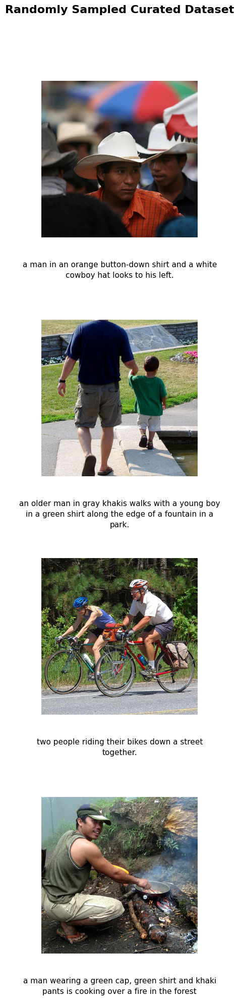

In [33]:
# Step 4 Verification

random_images = []
random_captions = []
missing_files = []

print(f"--- Starting Randomized Verification ({NV_SAMPLES} samples) ---")

actual_sample_size = min(NV_SAMPLES, len(df_curated))
sample_df = df_curated.sample(n=actual_sample_size)

for _, row in sample_df.iterrows():
    img_id = row['image_id']
    caption = row['caption']
    path = os.path.join(CURATED_DIR, img_id)
    
    if os.path.exists(path):
        try:
            img = Image.open(path).convert("RGB")
            random_images.append(img)
            random_captions.append(caption)
        except Exception as e:
            print(f"  ❌ Error loading {img_id}: {e}")
    else:
        missing_files.append(img_id)

if missing_files:
    print(f"⚠️ Warning: Missing files: {missing_files}")

if len(random_images) > 0:
    print(f"✅ Successfully loaded {len(random_images)} images.")
    # Call the new grid function
    display_experiment_feed(
        images=random_images, 
        captions=random_captions,
        title="Randomly Sampled Curated Dataset"
    )
else:
    print("❌ No images available to display.")

## Task 2 - CLIP Text Image Embedding Pipeline

Load CLIP ViT-B/32 and verify the text embedding and image embedding pipeline end-to-end on a sample of curated pairs.

1. Load the CLIP model and processor.
2. Tokenise and compute text and image embeddings on a sample
3. Verify alignment: mean cosine similarity on matched pairs vs random pairs.
4. Project embeddings with PCA and visualise the joint space.

In [34]:
# Step 1 Load CLIP
clip_model     = CLIPModel.from_pretrained(CLIP_MODEL_NAME).to(DEVICE).eval()
clip_processor = CLIPProcessor.from_pretrained(CLIP_MODEL_NAME)

print(f"CLIP loaded: {CLIP_MODEL_NAME}")
print(f"Parameters:  {sum(p.numel() for p in clip_model.parameters()):,}")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP loaded: openai/clip-vit-base-patch32
Parameters:  151,277,313


In [35]:
# Step 2 - Tokenise and compute text and image embeddings on a sample
N_SAMPLE = min(75, len(df_curated))
sample_df = df_curated.head(N_SAMPLE)

texts = [caption for caption in sample_df['caption']]
images = [
    Image.open(os.path.join(CURATED_DIR, image_id))
    .convert("RGB")
    .resize(IMG_SIZE)
    for image_id in sample_df['image_id']
]

inputs = clip_processor(text=texts, images=images, return_tensors="pt", padding=True).to(DEVICE)

with torch.no_grad():
    outputs      = clip_model(**inputs)
    text_embeds  = outputs.text_embeds
    image_embeds = outputs.image_embeds

print(f"Text embeddings:  {text_embeds.shape}")
print(f"Image embeddings: {image_embeds.shape}")

Text embeddings:  torch.Size([75, 512])
Image embeddings: torch.Size([75, 512])


In [36]:
# Step 3 - Verify alignment: matched vs random cosine similarity
text_norm  = torch.nn.functional.normalize(text_embeds,  dim=-1)
image_norm = torch.nn.functional.normalize(image_embeds, dim=-1)

sim_matrix = (text_norm @ image_norm.T).cpu().numpy()
matched_sim = np.diag(sim_matrix)

mask = ~np.eye(N_SAMPLE, dtype=bool)
random_sim = sim_matrix[mask].mean()

print(f"Matched-pair mean cosine sim: {matched_sim.mean():.4f}")
print(f"Random-pair mean cosine sim: {random_sim:.4f}")
print(f"Gap: {matched_sim.mean() - random_sim:.4f}")

Matched-pair mean cosine sim: 0.3295
Random-pair mean cosine sim: 0.1693
Gap: 0.1602


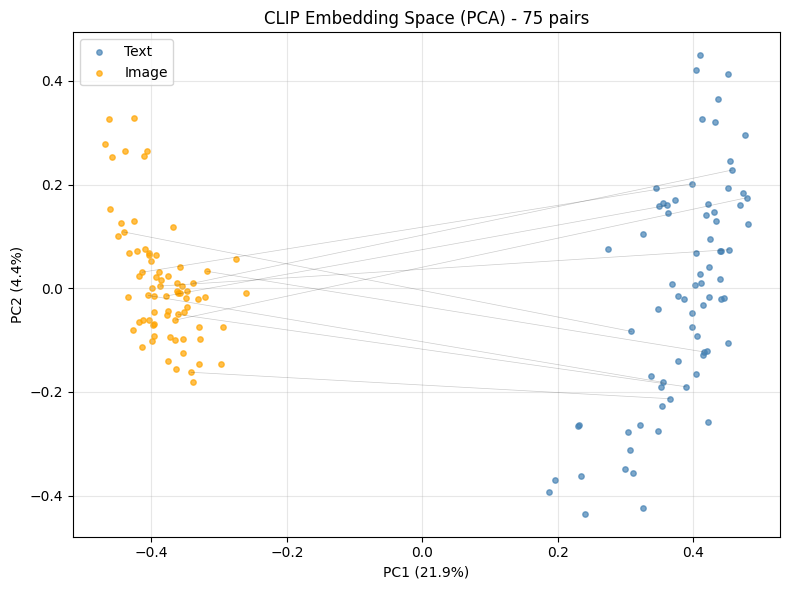

In [37]:
# Step 4 - PCA projection of joint embedding space
all_embeds = np.concatenate([text_embeds.cpu().numpy(), image_embeds.cpu().numpy()], axis=0)
pca = PCA(n_components=2, random_state=GLOBAL_SEED)
proj = pca.fit_transform(all_embeds)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(proj[:N_SAMPLE, 0], proj[:N_SAMPLE, 1], c='steelblue', s=15, label='Text', alpha=0.7)
ax.scatter(proj[N_SAMPLE:, 0], proj[N_SAMPLE:, 1], c='orange', s=15, label='Image', alpha=0.7)
for i in range(min(10, N_SAMPLE)):
    ax.plot([proj[i,0], proj[N_SAMPLE+i,0]], [proj[i,1], proj[N_SAMPLE+i,1]], 'k-', alpha=0.2, lw=0.5)
ax.set_title(f"CLIP Embedding Space (PCA) - {N_SAMPLE} pairs")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("pca.png")
plt.show()

## Task 3 - Baseline Stable Diffusion Generation

Generate images for 16 representative prompts drawn from the curated dataset using a pretrained Stable Diffusion v1-5 pipeline. Compare generated outputs against ground-truth images.

1. Load the Stable Diffusion pipeline.
2. Select 16 representative prompts from the curated dataset.
3. Generate one image per prompt (seed=42, guidance=10.0, 50 steps).
4. Display side-by-side: ground-truth vs generated, with prompt labels.
5. Save the gallery.

In [38]:
# Step 1 - Load Stable Diffusion pipeline
t0 = time.time()
sd_pipe = StableDiffusionPipeline.from_pretrained(
    SD_MODEL_NAME,
    torch_dtype=torch.float16 if DEVICE.type == "cuda" else torch.float32,
)
sd_pipe = sd_pipe.to(DEVICE)
sd_pipe.safety_checker = None
print(f"Stable Diffusion loaded in {time.time()-t0:.1f}s")
print("✅ Safety Checker disabled (Universal Signature Mode).")

\\PEMBROKE\davidfung\Education\ie7615_project2\lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Cannot initialize model with low cpu memory usage because `accelerate` was not found in the environment. Defaulting to `low_cpu_mem_usage=False`. It is strongly recommended to install `accelerate` for faster and less memory-intense model loading. You can do so with: 
```
pip install accelerate
```
.


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Stable Diffusion loaded in 2.2s
✅ Safety Checker disabled (Universal Signature Mode).


In [39]:
# Step 2 - Select representative prompts (evenly spaced)
 
indices = np.linspace(0, len(df_curated) - 1, NUM_GENERATIONS, dtype=int)
prompts = [df_curated.iloc[i]['caption'] for i in indices]
gt_images = [
    Image.open(os.path.join(CURATED_DIR, df_curated.iloc[i]['image_id']))
    .convert("RGB")
    .resize(IMG_SIZE)
    for i in indices
]
print(f"Selected {len(prompts)} prompts")
for item in prompts:
    print(f"- {item}")

Selected 16 prompts
- two young guys with shaggy hair look at their hands while hanging out in the yard.
- a man wearing a yellow shirt and tan pants plays golf outside while being watched by other people.
- three people wearing colorful costumes and masks sitting between two stone statues.
- a man in jeans and a white t-shirt chops up vegetables in a kitchen.
- a man with a white shirt and rubber boots is climbing on tanks in order to retrieve items from a specific tank.
- the girl is wearing a white shirt with pink skirt, and she is standing in front of a house.
- a young man, in a baseball cap and blue striped shirt, is playing the guitar.
- a woman in a red hat sits on a winding purple and bright green bench with a bush in the background.
- a boy in blue and red goggles is swimming.
- a girl in a purple dress smiling as she climbs an indoor rock wall.
- the little boy with the yellow stripe on his hat is in the snow.
- a black dog is attempting to catch a thrown object that is red.

In [40]:
# Step 3
generated_images = []
gen_times = []
NEGATIVE_PROMPT = "abstract, surreal, cartoon, drawing, painting, deformed, blurry, low quality, disfigured, extra limbs, watermark, text, error, distorted, dark, messy"

print(f"Starting generation for {min(NUM_GENERATIONS, len(prompts))} images...")

for i, p in enumerate(prompts[:NUM_GENERATIONS]):
    t0 = time.time() 
    try:
        prompt_string = str(p)
        
        result = sd_pipe(
            prompt=prompt_string,
            negative_prompt=NEGATIVE_PROMPT,           
            num_inference_steps=NUM_INFER_STEPS, 
            guidance_scale=GUIDANCE_SCALE,
            height=IMG_SIZE[0], 
            width=IMG_SIZE[1],
            safety_checker=None,
            generator=torch.Generator(device=DEVICE).manual_seed(GLOBAL_SEED + i)
        )

        img_out = result.images[0]
        generated_images.append(img_out)
        
        elapsed = time.time() - t0
        gen_times.append(elapsed)
        print(f"  [{i+1}/{NUM_GENERATIONS}] {elapsed:.1f}s")
        
    except Exception as e:
        print(f"  ❌ Error generating image {i}: {e}")

print(f"\n✅ Generation Complete. Generated {len(generated_images)} images.")

Starting generation for 16 images...


  0%|          | 0/50 [00:00<?, ?it/s]

  [1/16] 87.4s


  0%|          | 0/50 [00:00<?, ?it/s]

  [2/16] 87.7s


...

  [14/16] 89.9s


  0%|          | 0/50 [00:00<?, ?it/s]

  [15/16] 90.4s


  0%|          | 0/50 [00:00<?, ?it/s]

  [16/16] 87.3s

✅ Generation Complete. Generated 16 images.


--- Generating 16 individual comparison plots ---


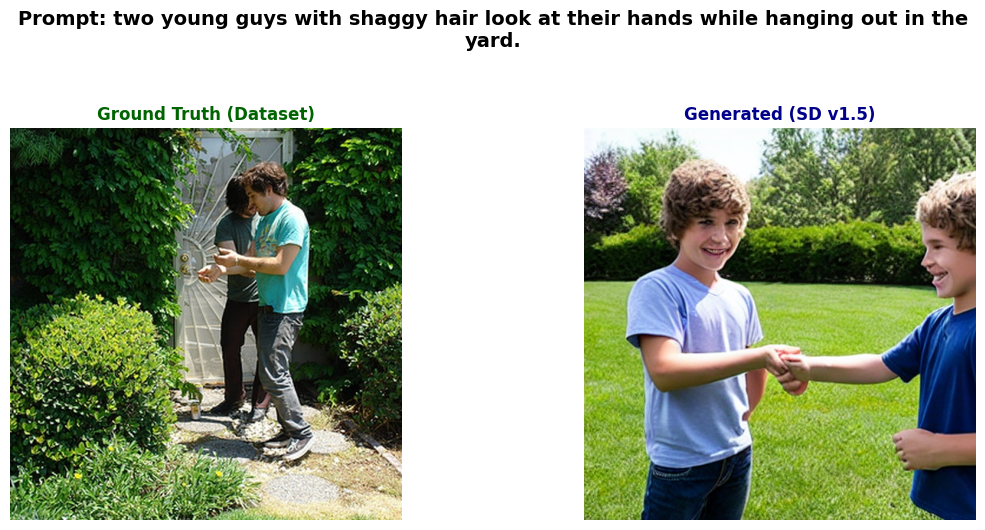

  [✓] Saved comparison 0 to gallery\comparison_pair_00.png


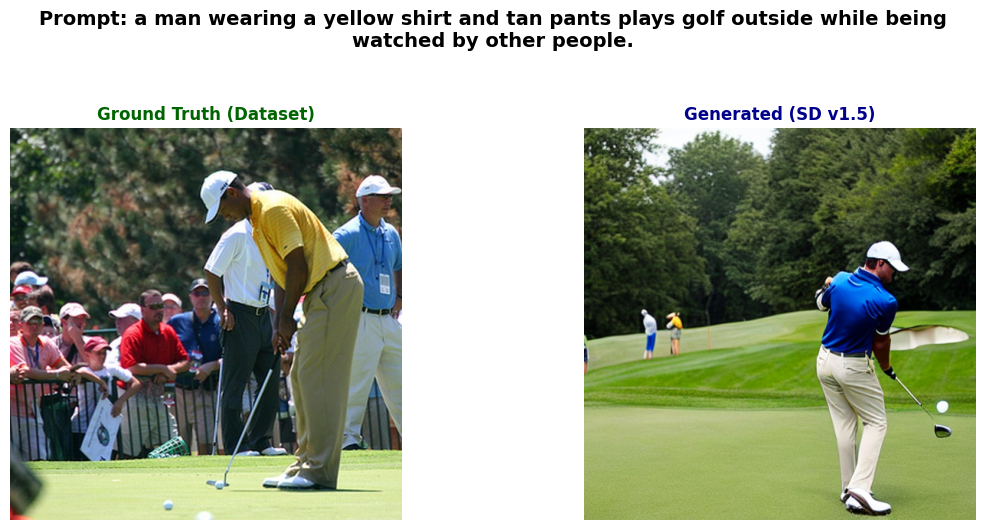

  [✓] Saved comparison 1 to gallery\comparison_pair_01.png


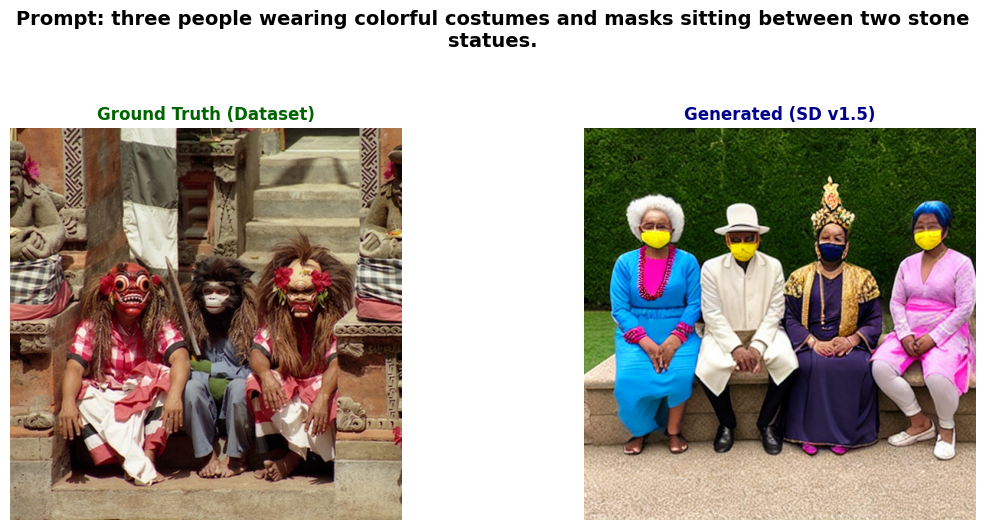

  [✓] Saved comparison 2 to gallery\comparison_pair_02.png


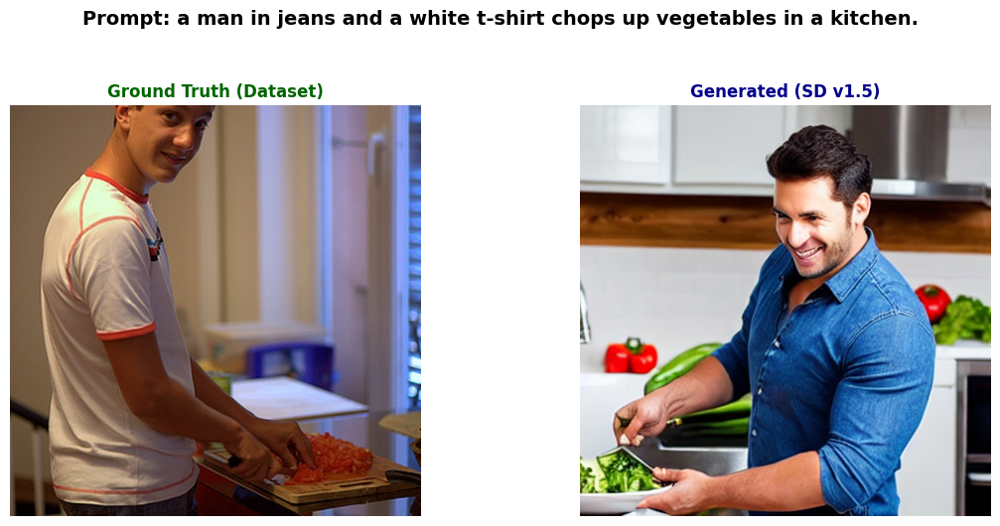

  [✓] Saved comparison 3 to gallery\comparison_pair_03.png


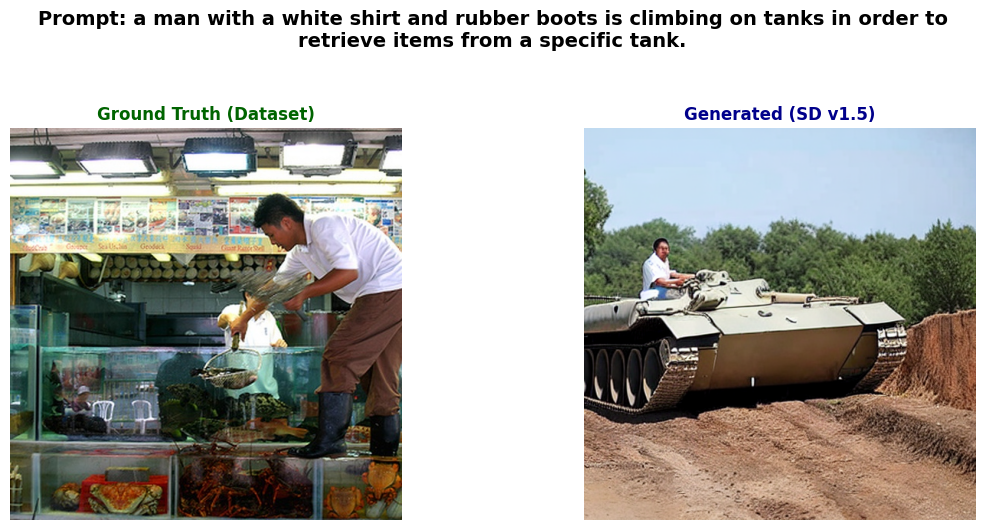

  [✓] Saved comparison 4 to gallery\comparison_pair_04.png


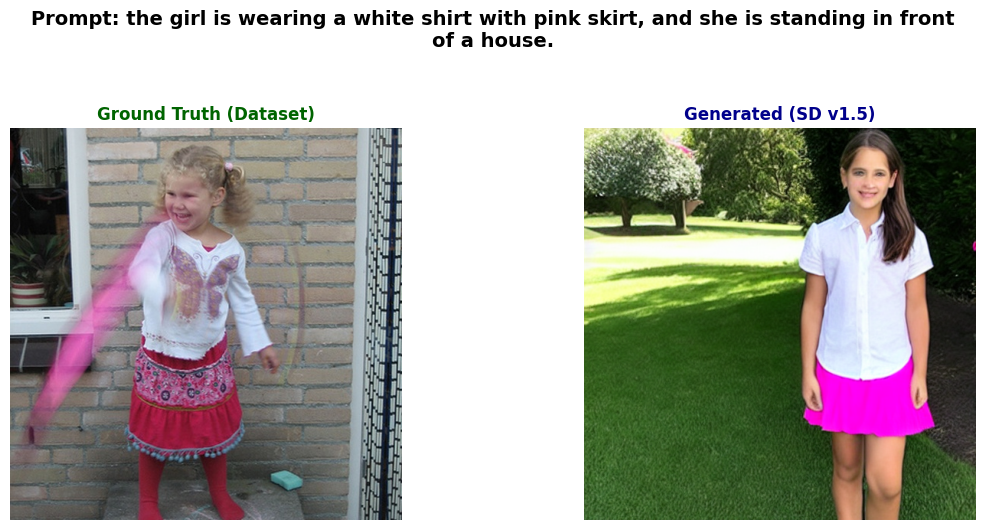

  [✓] Saved comparison 5 to gallery\comparison_pair_05.png


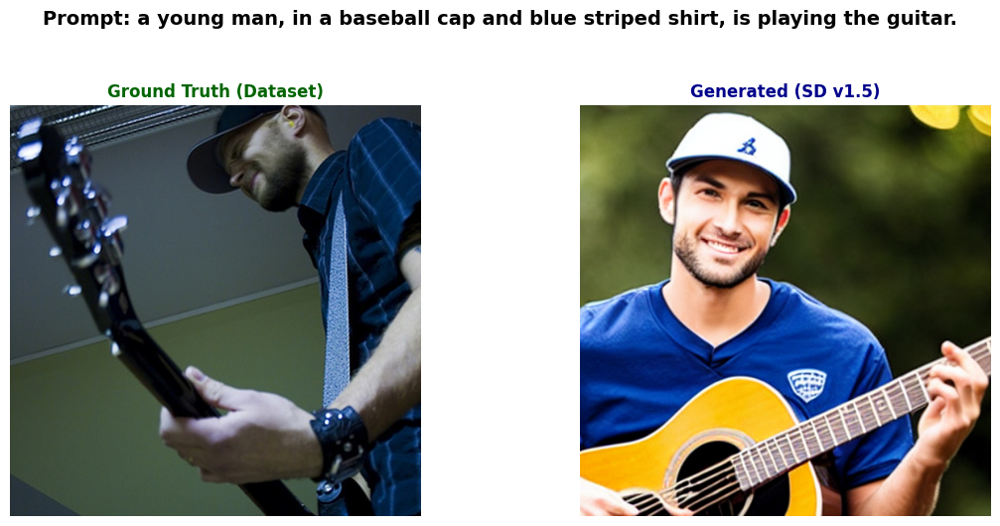

  [✓] Saved comparison 6 to gallery\comparison_pair_06.png


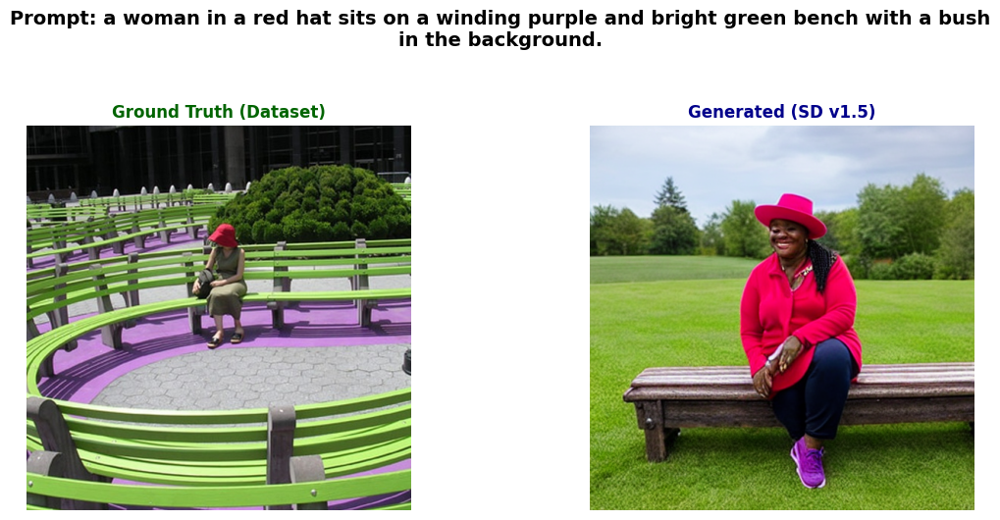

  [✓] Saved comparison 7 to gallery\comparison_pair_07.png


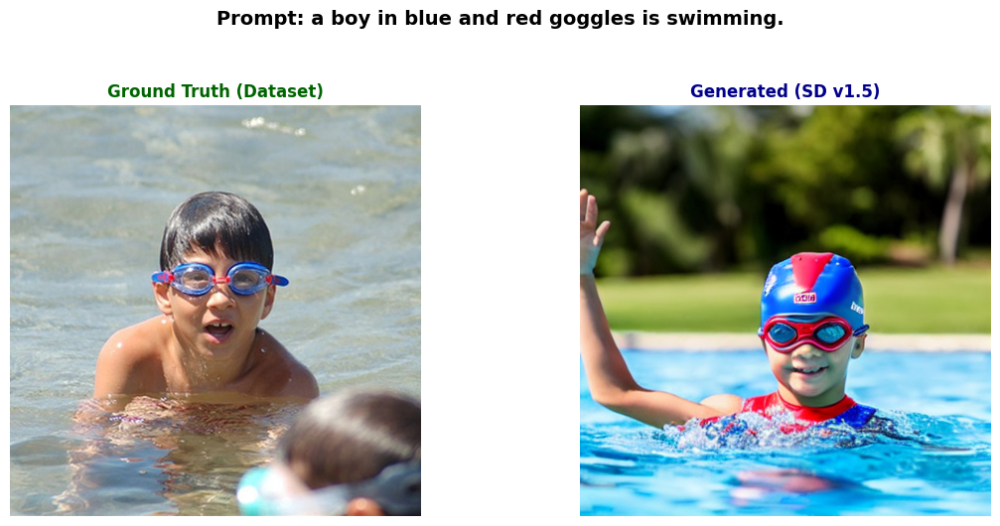

  [✓] Saved comparison 8 to gallery\comparison_pair_08.png


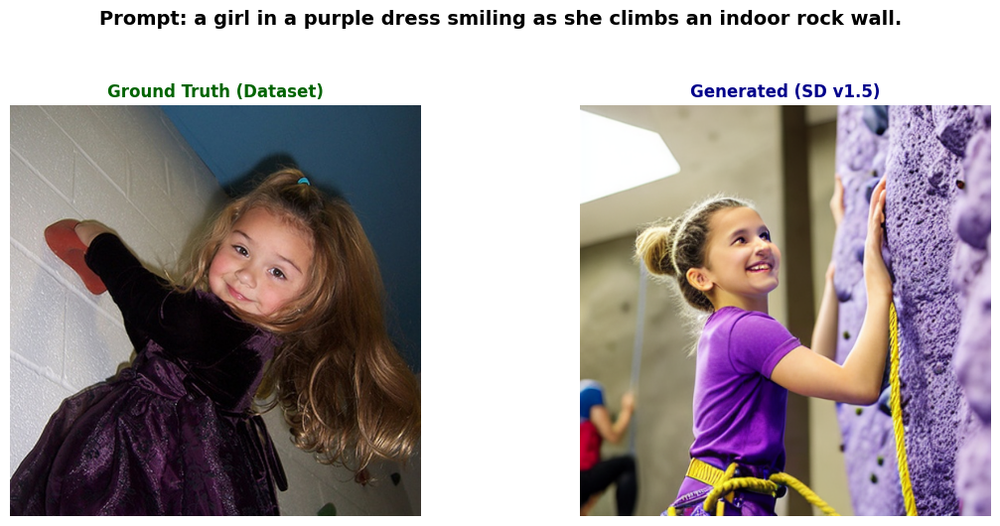

  [✓] Saved comparison 9 to gallery\comparison_pair_09.png


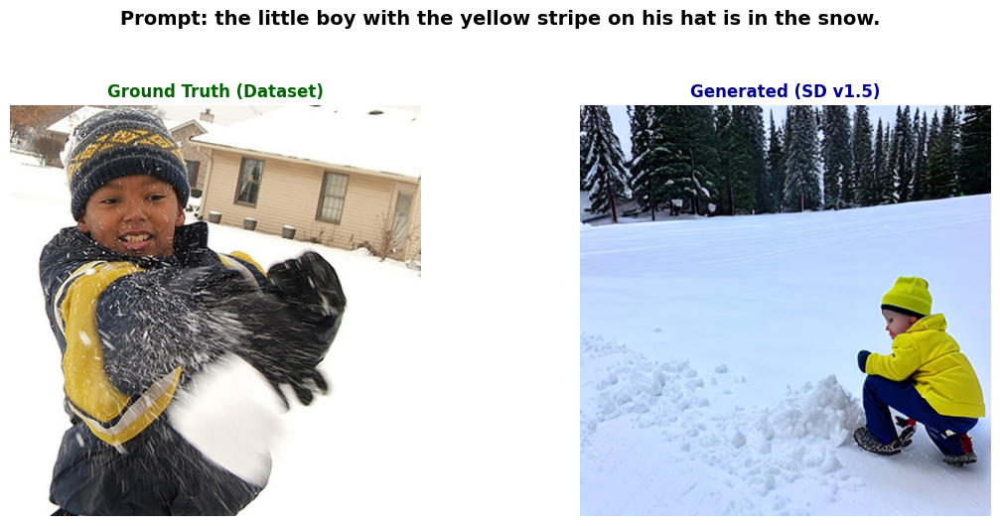

  [✓] Saved comparison 10 to gallery\comparison_pair_10.png


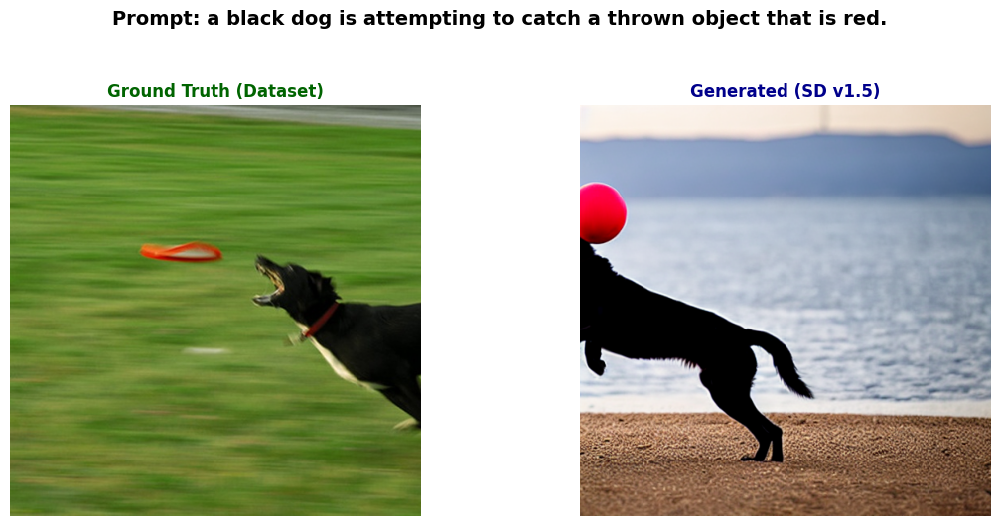

  [✓] Saved comparison 11 to gallery\comparison_pair_11.png


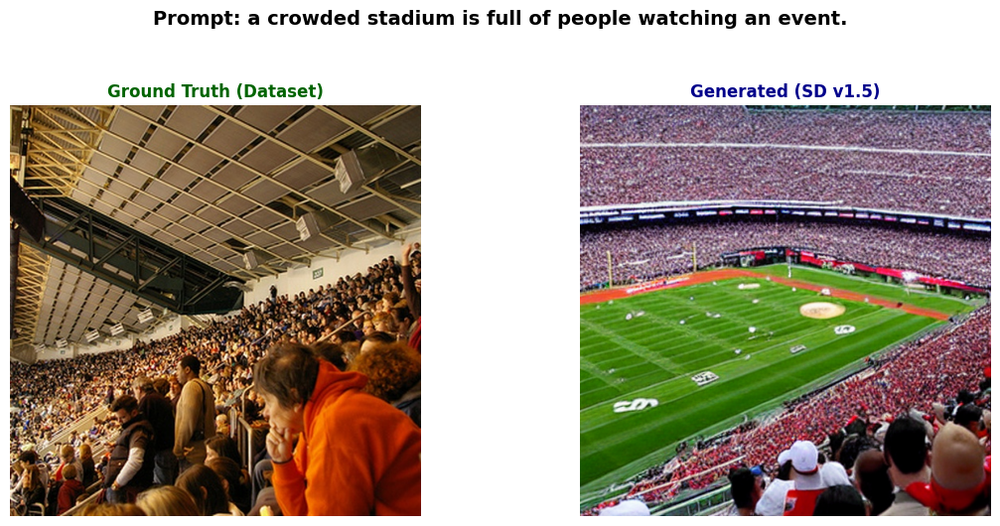

  [✓] Saved comparison 12 to gallery\comparison_pair_12.png


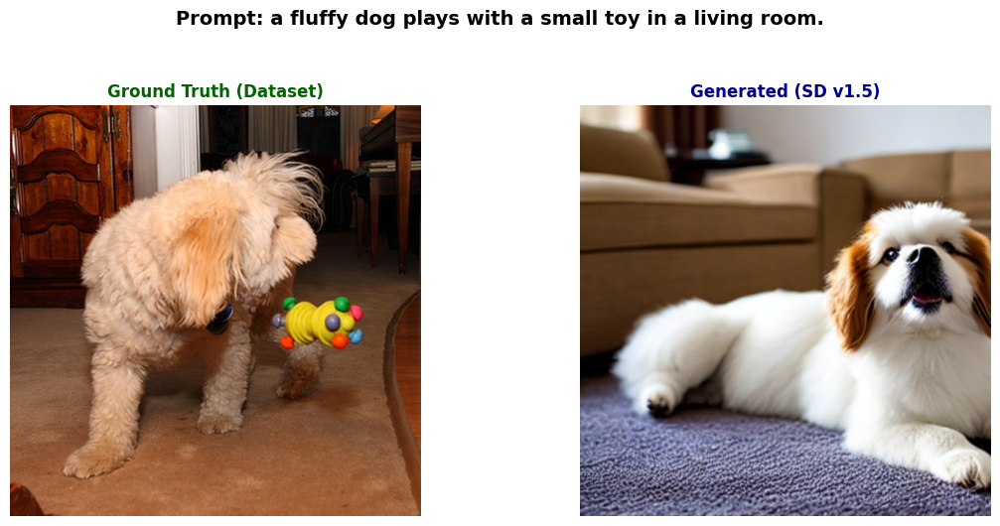

  [✓] Saved comparison 13 to gallery\comparison_pair_13.png


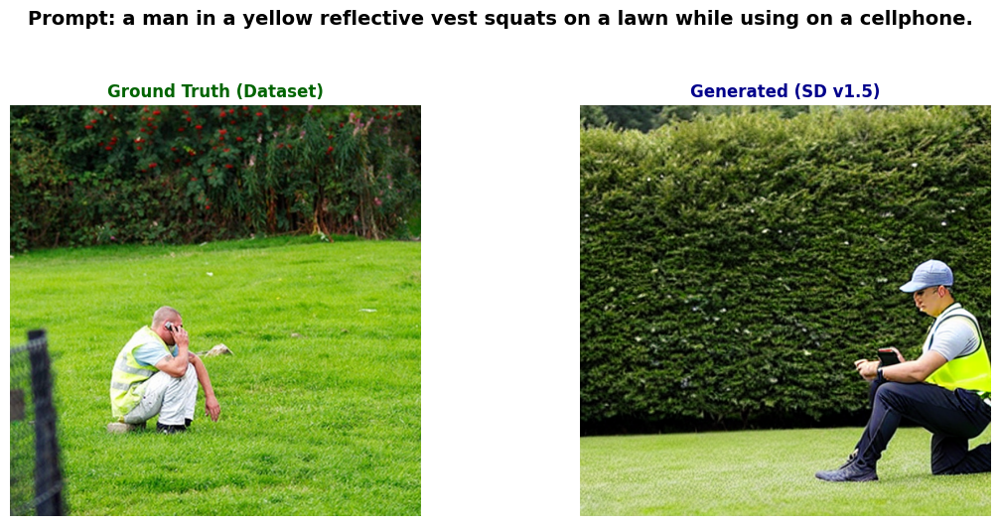

  [✓] Saved comparison 14 to gallery\comparison_pair_14.png


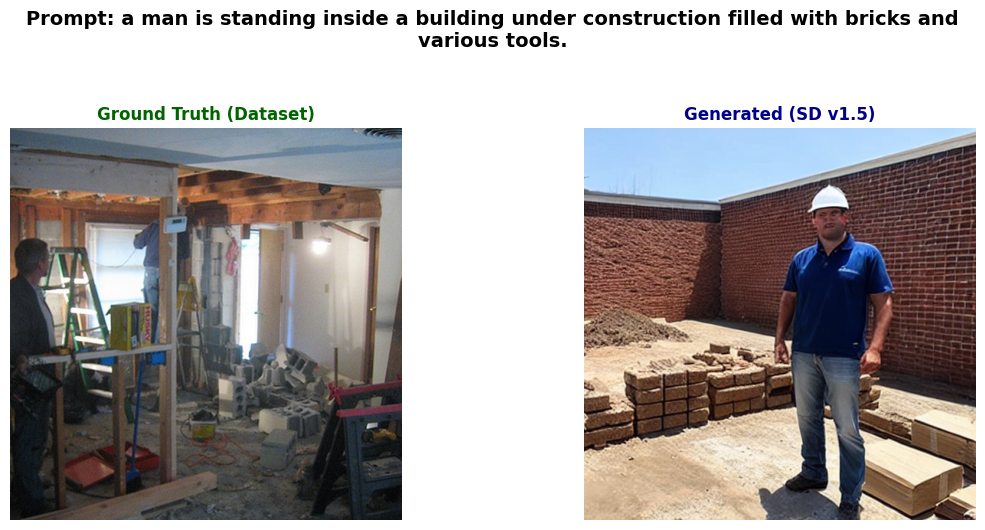

  [✓] Saved comparison 15 to gallery\comparison_pair_15.png

✅ All 16 comparison plots have been saved to: gallery


In [41]:
# --- Step 4: Side-by-side Comparison  ---

def text_wrap_logic(text, width):
    return "\n".join(textwrap.wrap(text, width=width))

comparison_paths = []

print(f"--- Generating {NUM_GENERATIONS} individual comparison plots ---")

for i in range(NUM_GENERATIONS):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    
    prompt_text = prompts[i]
    wrapped_prompt = text_wrap_logic(prompt_text, width=80) # Using a helper or inline
    
    axes[0].imshow(gt_images[i])
    axes[0].set_title("Ground Truth (Dataset)", fontsize=12, fontweight='bold', color='darkgreen')
    axes[0].axis("off")
    
    axes[1].imshow(generated_images[i])
    axes[1].set_title("Generated (SD v1.5)", fontsize=12, fontweight='bold', color='darkblue')
    axes[1].axis("off")
    
    fig.suptitle(f"Prompt: {wrapped_prompt}", fontsize=14, fontweight='bold', y=1.05)
    
    # 7. Save the individual comparison figure
    comp_filename = f"comparison_pair_{i:02d}.png"
    comp_path = os.path.join(GALLERY_DIR, comp_filename)
    
    plt.tight_layout()
    plt.savefig(comp_path, bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)
    
    comparison_paths.append(comp_path)
    print(f"  [✓] Saved comparison {i} to {comp_path}")

print(f"\n✅ All {NUM_GENERATIONS} comparison plots have been saved to: {GALLERY_DIR}")

## Cleanup

In [42]:
del clip_model, clip_processor, sd_pipe
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print("Milestone 1 complete.")

Milestone 1 complete.
